| Subject Code | Assignment No. |
|:------------:|:--------------:|
| CS69101      | Lab 6          |

Given a set of integer elements stored in an input file, `input.txt`, construct a **Segment Tree** to efficiently perform **Range Minimum Query (RMQ)** and **Range Maximum Query** operations.

The Segment Tree should store both the minimum and maximum values corresponding to each segment of the input array. Implement range query and point update operations while maintaining the correctness of the Segment Tree.

In [1]:
import os
import sys
from io import TextIOWrapper
from typing import Self, Any, Callable, TypeVar, Generic, Optional
import random
import sys
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.pylab import figure

sys.setrecursionlimit(100000) # Fix to avoid RecursionError

DATA_DIR = "./lab6_data"
os.makedirs(DATA_DIR, exist_ok=True)

prep_arr = [random.randint(1, (i+1)*10) for i in range(10000)] # Random Array of 10000 Elements
# prep_arr.sort() # Sorted Array for Worst Case Scenario
print(prep_arr[:25])
print(len(prep_arr))

# Write the array to a file
f = open(f"{DATA_DIR}/input0.txt", "w")
for i in prep_arr:
    f.write(f"{i}, ")
f.write("\n")
f.close()

del prep_arr
del f

iterations = 0
PRINT_DEBUG = False

[8, 12, 20, 40, 2, 11, 10, 31, 11, 57, 109, 39, 87, 26, 144, 126, 162, 57, 1, 184, 206, 15, 149, 185, 208]
10000


# Q1.

Read integer elements from `input.txt` and construct a Segment Tree using the given array elements.

## File Read

In [2]:
# Read a set of integer elements from an input file (input.txt)
def read_ints(path: str) -> list[int]:
    # Elements may be separated by spaces and/or commas, over one or more lines
    try:
        with open(path, 'r') as data:
            return [int(token) for line in data for token in line.replace(',', ' ').split()]
    except (OSError, ValueError) as e:
        sys.exit("[ERROR] Invalid data" + str(e))

arr0 = read_ints(f"{DATA_DIR}/input.txt")
n = len(arr0)
assert n >= 4, "input.txt must contain at least 4 integer elements"

In [3]:
print(arr0)

[12, 5, 18, 3, 9, 21, 7, 14]


## Segment Tree

In [4]:
# LEGACY CODE LOL

# class Segment_Node:
#     def __init__(self, value: int | None = None):
#         self.__lchild = None
#         self.__rchild = None
#         self.__value = None

#     def find_leaf(self) -> Self:
#         if self.__lchild is None and self.__rchild is None:
#             return self
#         elif self.__lchild is not None:
#             return self.__lchild.find_leaf()
#         else:
#             assert self.__rchild is not None # This is to shut the LSP up.
#             return self.__rchild.find_leaf()
    
#     def insert(self, value: int) -> Self: # Guess why this is wrong.
#         if self.__value is None:
#             self.__value = value
#         if self.__value == value:
#             return self
#         elif value < self.__value: #
#             if self.__lchild is None:
#                 new_node = type(self)(value) # type(self) instead of Segment_Node to shut the linter up.
#                 self.__lchild = (new_node)
#             else:
#                 self.__lchild.insert(value)
#         else:
#             if self.__rchild is None:
#                 new_node = type(self)(value)
#                 self.__rchild = new_node
#             else:
#                 self.__rchild.insert(value)
#         return self

In [5]:
class Segment_Tree:
    def __init__(self):
        self.__size = 0
        self.__min = []  # minimum of every segment (heap-indexed: children of i are 2i+1 and 2i+2)
        self.__max = []  # maximum of every segment

    def __node(self, index: int) -> tuple[int, int]:
        return (self.__min[index], self.__max[index])

    # Q4: combine the (minimum, maximum) results of two child nodes
    def merge(self, left: tuple[int, int], right: tuple[int, int]) -> tuple[int, int]:
        return (min(left[0], right[0]), max(left[1], right[1]))

    # Q2: build the tree over arr; every node stores the minimum and the maximum of its segment
    def build(self, arr: list[int], left_bound: int = 0, right_bound: int | None = None, index: int = 0) -> None:
        global iterations
        if right_bound is None:  # top-level call: allocate the tree for len(arr) elements
            assert len(arr) > 0, "Cannot build a Segment Tree over an empty array"
            self.__size = len(arr)
            self.__min = [0] * 4 * self.__size
            self.__max = [0] * 4 * self.__size
            right_bound = self.__size - 1
        iterations += 1  # one node visited
        if left_bound == right_bound:
            self.__min[index] = self.__max[index] = arr[left_bound]
            return
        mid = (left_bound + right_bound) // 2
        left_child_index = index * 2 + 1
        right_child_index = index * 2 + 2

        self.build(arr, left_bound, mid, left_child_index)
        self.build(arr, mid + 1, right_bound, right_child_index)

        self.__min[index], self.__max[index] = self.merge(self.__node(left_child_index), self.__node(right_child_index))

    # Q3: (minimum, maximum) of arr[query_start..query_end]
    def query(self, query_start: int, query_end: int, left_bound: int = 0, right_bound: int | None = None, index: int = 0) -> Optional[tuple[int, int]]:
        global iterations
        if right_bound is None:  # top-level call
            assert 0 <= query_start <= query_end < self.__size, f"Invalid range [{query_start}, {query_end}]"
            right_bound = self.__size - 1
        iterations += 1  # one node visited
        if right_bound < query_start or query_end < left_bound:
            return None  # segment lies completely outside the query range

        if query_start <= left_bound and right_bound <= query_end:
            return self.__node(index)  # segment lies completely inside the query range

        mid = (left_bound + right_bound) // 2
        left_child_index = index * 2 + 1
        right_child_index = index * 2 + 2

        left_result = self.query(query_start, query_end, left_bound, mid, left_child_index)
        right_result = self.query(query_start, query_end, mid + 1, right_bound, right_child_index)

        if left_result is not None and right_result is not None:
            return self.merge(left_result, right_result)
        elif left_result is not None:
            return left_result
        else:
            return right_result

    # Q5: set arr[target_index] = value and recompute every segment on the path to the root
    def update(self, target_index: int, value: int, left_bound: int = 0, right_bound: int | None = None, index: int = 0) -> None:
        global iterations
        if right_bound is None:  # top-level call
            assert 0 <= target_index < self.__size, f"Invalid index {target_index}"
            right_bound = self.__size - 1
        iterations += 1  # one node visited
        if left_bound == right_bound:
            self.__min[index] = self.__max[index] = value
            return
        mid = (left_bound + right_bound) // 2
        left_child_index = index * 2 + 1
        right_child_index = index * 2 + 2

        if target_index <= mid:
            self.update(target_index, value, left_bound, mid, left_child_index)
        else:
            self.update(target_index, value, mid + 1, right_bound, right_child_index)

        self.__min[index], self.__max[index] = self.merge(self.__node(left_child_index), self.__node(right_child_index))

    # Height in levels (a single node is 1)
    def height(self, left_bound: int = 0, right_bound: int | None = None) -> int:
        if right_bound is None:
            assert self.__size > 0, "The tree has not been built yet"
            right_bound = self.__size - 1
        if left_bound == right_bound:
            return 1
        mid = (left_bound + right_bound) // 2
        return 1 + max(self.height(left_bound, mid), self.height(mid + 1, right_bound))

    # Q6: one line per node, indented by depth (pre-order)
    def representation(self, left_bound: int = 0, right_bound: int | None = None, index: int = 0, depth: int = 0) -> list[str]:
        if right_bound is None:
            right_bound = self.__size - 1
        line = f"{'    ' * depth}[{left_bound}, {right_bound}]  minimum = {self.__min[index]}, maximum = {self.__max[index]}"
        if left_bound == right_bound:
            return [line]
        mid = (left_bound + right_bound) // 2
        return ([line]
                + self.representation(left_bound, mid, index * 2 + 1, depth + 1)
                + self.representation(mid + 1, right_bound, index * 2 + 2, depth + 1))

## Linear Range Search
Baseline for Q8: scan every element of `[query_start, query_end]` once, keeping the running minimum and maximum.

In [6]:
def linear_range_search(arr: list[int], query_start: int, query_end: int, index: int | None = None) -> tuple[int, int]:
    global iterations
    if index is None:
        index = query_start
    iterations += 1  # one element scanned
    if index == query_end:
        return (arr[index], arr[index])
    rest_min, rest_max = linear_range_search(arr, query_start, query_end, index + 1)
    return (min(arr[index], rest_min), max(arr[index], rest_max))

In [7]:
stree0 = Segment_Tree()

# Q2.

Implement the `build()` operation to construct the Segment Tree such that each node stores:

- Minimum value of its corresponding range.
- Maximum value of its corresponding range.

## build()

In [8]:
iterations = 0
stree0.build(arr0)

print(f"build() visited {iterations} nodes for {n} elements (2n - 1 = {2 * n - 1}).")
print(f"Tree height: {stree0.height()} levels")

build() visited 15 nodes for 8 elements (2n - 1 = 15).
Tree height: 4 levels


# Q3.

Implement `query(L, R)` to find:

- Minimum element in the range [L, R].
- Maximum element in the range [L, R].

## Query File Read

In [9]:
# queries.txt: the number of range queries, followed by one "L R" pair per line
queries = []
try:
    data1 = open(f"{DATA_DIR}/queries.txt", 'r')
    num_queries = int(data1.readline())
    for _ in range(num_queries):
        left, right = map(int, data1.readline().split())
        assert 0 <= left <= right < n, f"Query [{left}, {right}] is outside the array"
        queries.append((left, right))
    data1.close()
except Exception as e:
    sys.exit("[ERROR] Invalid queries" + str(e))

print(queries)

[(0, 3), (2, 6), (1, 5), (4, 7)]


## query()

In [10]:
def verify_queries(tree: Segment_Tree, arr: list[int], max_checks: int = 500) -> None:
    # Compare the tree with brute force on every range (or on a random subset of max_checks ranges)
    ranges = [(l, r) for l in range(len(arr)) for r in range(l, len(arr))]
    if len(ranges) > max_checks:
        ranges = random.sample(ranges, max_checks)
    for left, right in ranges:
        assert tree.query(left, right) == (min(arr[left:right + 1]), max(arr[left:right + 1])), f"query({left}, {right}) is wrong"
    print(f"Verified {len(ranges)} range queries against brute force.")

random.seed(911)  # reproducible random checks and updates
verify_queries(stree0, arr0)

Verified 36 range queries against brute force.


# Q4.

Implement a `merge()` operation to combine the results of two child nodes:

- minimum = min(left.minimum, right.minimum)
- maximum = max(left.maximum, right.maximum)

## merge()

In [11]:
# Merging the results of the two halves of the array must give the result for the whole array
half = n // 2
left_result, right_result = stree0.query(0, half - 1), stree0.query(half, n - 1)
merged = stree0.merge(left_result, right_result)
assert merged == stree0.query(0, n - 1)
print(f"merge({left_result}, {right_result}) = {merged}")

merge((3, 18), (7, 21)) = (3, 21)


# Q5.

Implement `update(index, value)` to modify an element at a specified index and update all affected nodes of the Segment Tree.

## update()

In [12]:
# Updates are applied to a separate copy so that stree0 is untouched for Q6
check_arr = arr0.copy()
check_tree = Segment_Tree()
check_tree.build(check_arr)

for _ in range(20):
    index, value = random.randrange(n), random.randint(1, 10 * n)
    check_tree.update(index, value)
    check_arr[index] = value

verify_queries(check_tree, check_arr)

Verified 36 range queries against brute force.


# Q6.

Display the following after construction:

- Original array.
- Segment Tree representation.
- Minimum value of a specified range.
- Maximum value of the same range.

The result after every point update is displayed as well, and everything is stored in `output.txt`.

## Display

In [13]:
output_lines = []

def emit(line: str = "") -> None:
    print(line)
    output_lines.append(line)

def emit_query(tree: Segment_Tree, left: int, right: int) -> None:
    minimum, maximum = tree.query(left, right)
    emit(f"Query [{left}, {right}]")
    emit(f"Minimum = {minimum}")
    emit(f"Maximum = {maximum}")

emit("Original array:")
emit(" ".join(map(str, arr0)))
emit()
emit("Segment Tree:")
for line in stree0.representation():
    emit(line)
emit()

for left, right in queries:
    emit_query(stree0, left, right)
    emit()

# The first update is the one from the assignment's example; the others are random
updates = [(3, 25)] + [(random.randrange(n), random.randint(1, 10 * n)) for _ in range(2)]
current = arr0.copy()
for index, value in updates:
    stree0.update(index, value)
    current[index] = value
    assert stree0.query(0, n - 1) == (min(current), max(current))
    emit("Update:")
    emit(f"Index = {index}")
    emit(f"New Value = {value}")
    emit_query(stree0, 0, n - 1)
    emit()

Original array:
12 5 18 3 9 21 7 14

Segment Tree:
[0, 7]  minimum = 3, maximum = 21
    [0, 3]  minimum = 3, maximum = 18
        [0, 1]  minimum = 5, maximum = 12
            [0, 0]  minimum = 12, maximum = 12
            [1, 1]  minimum = 5, maximum = 5
        [2, 3]  minimum = 3, maximum = 18
            [2, 2]  minimum = 18, maximum = 18
            [3, 3]  minimum = 3, maximum = 3
    [4, 7]  minimum = 7, maximum = 21
        [4, 5]  minimum = 9, maximum = 21
            [4, 4]  minimum = 9, maximum = 9
            [5, 5]  minimum = 21, maximum = 21
        [6, 7]  minimum = 7, maximum = 14
            [6, 6]  minimum = 7, maximum = 7
            [7, 7]  minimum = 14, maximum = 14

Query [0, 3]
Minimum = 3
Maximum = 18

Query [2, 6]
Minimum = 3
Maximum = 21

Query [1, 5]
Minimum = 3
Maximum = 21

Query [4, 7]
Minimum = 7
Maximum = 21

Update:
Index = 3
New Value = 25
Query [0, 7]
Minimum = 5
Maximum = 25

Update:
Index = 2
New Value = 57
Query [0, 7]
Minimum = 5
Maximum = 57

Up

## Output

In [14]:
with open(f"{DATA_DIR}/output.txt", "w") as out_file:
    out_file.write("\n".join(output_lines).rstrip("\n") + "\n")

# Q7.

For different numbers of elements, such as 100, 500, 1000, 5000 and 10000, measure and plot:

- Construction Time vs. Number of Elements
- Range Query Time vs. Number of Elements
- Point Update Time vs. Number of Elements
- Tree Height vs. Number of Elements

Time is measured as the number of iterations: one iteration is one node visited (one element scanned for the linear search).

**Method.** For every size *n*, a window of *n* consecutive elements starting at a random position of `input0.txt` is used as the array. Each reported value is the mean of `TRIALS` independent windows. Query cost is the average over `NUM_OPS` random ranges `[L, R]`, and update cost is the average over `NUM_OPS` random point updates.

## Experiment Setup

In [15]:
SIZES = [100, 500, 1000, 5000, 10000]
TRIALS = 3
NUM_OPS = 100
INPUT0 = read_ints(f"{DATA_DIR}/input0.txt")


def random_window(arr: list[int], n: int) -> list[int]:
    # n consecutive elements of arr starting at a random position
    assert n <= len(arr), "n cannot exceed the length of the input pool"
    start = random.randint(0, len(arr) - n)
    return arr[start:start + n]


def counted(fn, *args):
    # Run fn(*args) and return (result, iterations used by that single call)
    global iterations
    iterations = 0
    result = fn(*args)
    return result, iterations


def measure(values: list[int], queries: list[tuple[int, int]], updates: list[tuple[int, int]]) -> dict:
    stree = Segment_Tree()
    _, build_iterations = counted(stree.build, values)
    height = stree.height()

    query_counts, linear_counts = [], []
    for left, right in queries:
        result, count = counted(stree.query, left, right)
        expected, linear_count = counted(linear_range_search, values, left, right)
        assert result == expected, f"query({left}, {right}) disagrees with linear search"
        query_counts.append(count)
        linear_counts.append(linear_count)

    current, update_counts = values.copy(), []
    for index, value in updates:
        update_counts.append(counted(stree.update, index, value)[1])
        current[index] = value
    assert stree.query(0, len(current) - 1) == (min(current), max(current)), "tree is wrong after the updates"

    return {
        "Height": height,
        "Construction Iterations": build_iterations,
        "Average Query Iterations": sum(query_counts) / len(query_counts),
        "Average Linear Search Iterations": sum(linear_counts) / len(linear_counts),
        "Average Update Iterations": sum(update_counts) / len(update_counts),
    }


def run_experiment(orders: list[str]) -> pd.DataFrame:
    # Mean of every metric over TRIALS random windows, for each size and input order
    rows = []
    for n in SIZES:
        for _ in range(TRIALS):
            window = random_window(INPUT0, n)
            query_ranges = []
            for _ in range(NUM_OPS):
                left = random.randrange(n)
                query_ranges.append((left, random.randrange(left, n)))
            point_updates = [(random.randrange(n), random.randint(1, 10 * n)) for _ in range(NUM_OPS)]
            input_orders = {
                "Random": window,
                "Sorted": sorted(window),
                "Reverse Sorted": sorted(window, reverse=True),
            }
            for order in orders:
                rows.append({"Elements": n, "Input Order": order,
                             **measure(input_orders[order], query_ranges, point_updates)})
    return pd.DataFrame(rows).groupby(["Elements", "Input Order"], sort=False).mean().reset_index()


def plot_metric(df: pd.DataFrame, series: dict[str, str], ylabel: str, title: str, fname: str) -> None:
    # One line per series; linear axes, y-axis starting at zero
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for label, column in series.items():
        ax.plot(df["Elements"], df[column], marker="o", label=label)
    ax.set_xlabel("Number of Elements")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", alpha=0.7)
    if len(series) > 1:
        ax.legend()
    fig.tight_layout()
    fig.savefig(f"{DATA_DIR}/{fname}", dpi=150, bbox_inches="tight")
    plt.show()


def plot_metric_by_order(df: pd.DataFrame, series: dict[str, str], ylabel: str, title: str, fname: str) -> None:
    # One panel per input order, each with its own y-scale
    orders = list(df["Input Order"].unique())
    fig, axes = plt.subplots(1, len(orders), figsize=(15, 4.5))
    for ax, order in zip(axes, orders):
        g = df[df["Input Order"] == order]
        for label, column in series.items():
            ax.plot(g["Elements"], g[column], marker="o", label=label)
        ax.set_title(order)
        ax.set_xlabel("Number of Elements")
        ax.set_ylabel(ylabel)
        ax.set_ylim(bottom=0)
        ax.grid(True, linestyle=":", alpha=0.7)
        if len(series) > 1:
            ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(f"{DATA_DIR}/{fname}", dpi=150, bbox_inches="tight")
    plt.show()

In [16]:
random.seed(911)
task7_df = run_experiment(orders=["Random"])
task7_df.drop(columns=["Input Order"])

,Elements,Height,Construction Iterations,Average Query Iterations,Average Linear Search Iterations,Average Update Iterations
0,100,8.0,199.0,19.120000,27.306667,7.716667
1,500,10.0,999.0,27.813333,129.586667,9.983333
2,1000,11.0,1999.0,31.433333,245.763333,10.976667
3,5000,14.0,9999.0,41.213333,1260.863333,13.366667
4,10000,15.0,19999.0,45.213333,2417.686667,14.346667


## Construction Time v/s Number of Elements

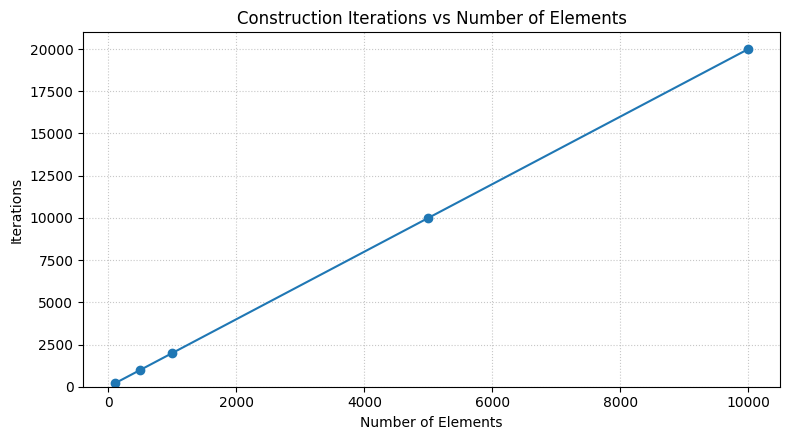

In [17]:
plot_metric(task7_df, {"Segment Tree": "Construction Iterations"}, "Iterations",
            "Construction Iterations vs Number of Elements", "q7_construction.png")

## Range Query Time v/s Number of Elements

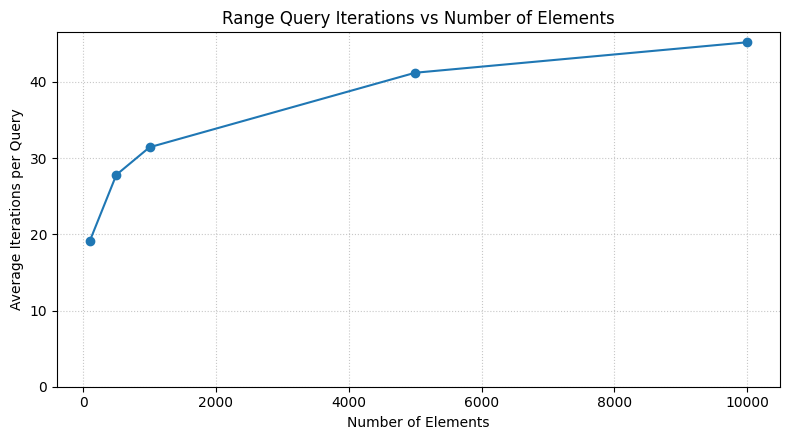

In [18]:
plot_metric(task7_df, {"Segment Tree": "Average Query Iterations"}, "Average Iterations per Query",
            "Range Query Iterations vs Number of Elements", "q7_query.png")

## Point Update Time v/s Number of Elements

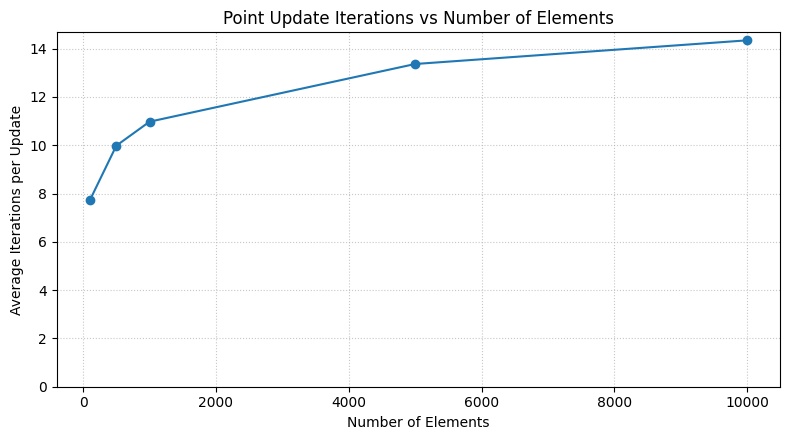

In [19]:
plot_metric(task7_df, {"Segment Tree": "Average Update Iterations"}, "Average Iterations per Update",
            "Point Update Iterations vs Number of Elements", "q7_update.png")

## Tree Height v/s Number of Elements

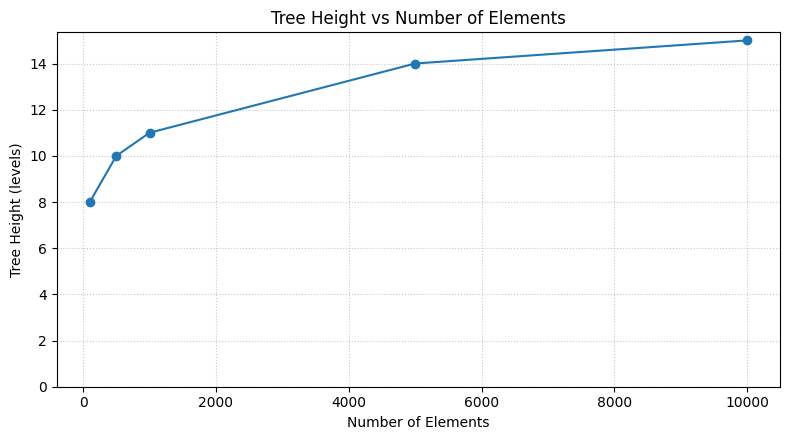

In [20]:
plot_metric(task7_df, {"Segment Tree": "Height"}, "Tree Height (levels)",
            "Tree Height vs Number of Elements", "q7_height.png")

# Q8.

Implement a linear-search-based approach for finding the minimum and maximum in a given range and experimentally compare its execution time with the Segment Tree approach.

The linear search (`linear_range_search`) is implemented above; every query of the experiment is answered by both approaches on the same array and range, and the two answers are asserted to be equal.

## Segment Tree v/s Linear Search (Query)

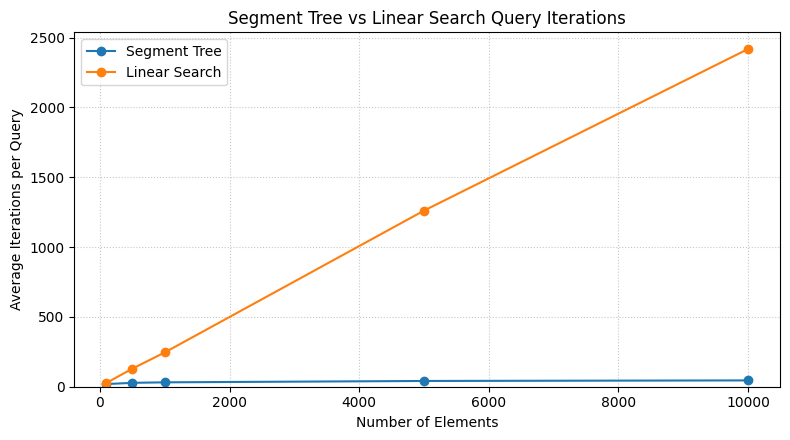

In [21]:
plot_metric(task7_df, {"Segment Tree": "Average Query Iterations",
                       "Linear Search": "Average Linear Search Iterations"},
            "Average Iterations per Query",
            "Segment Tree vs Linear Search Query Iterations", "q8_query_vs_linear.png")

# Q9.

Perform experiments using random, sorted, and reverse-sorted input data and provide a brief analysis of the results.

For each size, the same window, query ranges and updates are used in all three input orders (sorted and reverse-sorted are the sorted and reversed copies of the random window).

In [22]:
task9_df = run_experiment(orders=["Random", "Sorted", "Reverse Sorted"])
task9_df

,Elements,Input Order,Height,Construction Iterations,Average Query Iterations,Average Linear Search Iterations,Average Update Iterations
0,100,Random,8.0,199.0,18.733333,22.246667,7.693333
1,100,Sorted,8.0,199.0,18.733333,22.246667,7.693333
2,100,Reverse Sorted,8.0,199.0,18.733333,22.246667,7.693333
3,500,Random,10.0,999.0,27.666667,127.266667,9.976667
4,500,Sorted,10.0,999.0,27.666667,127.266667,9.976667
5,500,Reverse Sorted,10.0,999.0,27.666667,127.266667,9.976667
6,1000,Random,11.0,1999.0,31.766667,250.090000,10.973333
7,1000,Sorted,11.0,1999.0,31.766667,250.090000,10.973333
8,1000,Reverse Sorted,11.0,1999.0,31.766667,250.090000,10.973333
9,5000,Random,14.0,9999.0,40.766667,1186.920000,13.346667


## Construction Comparison

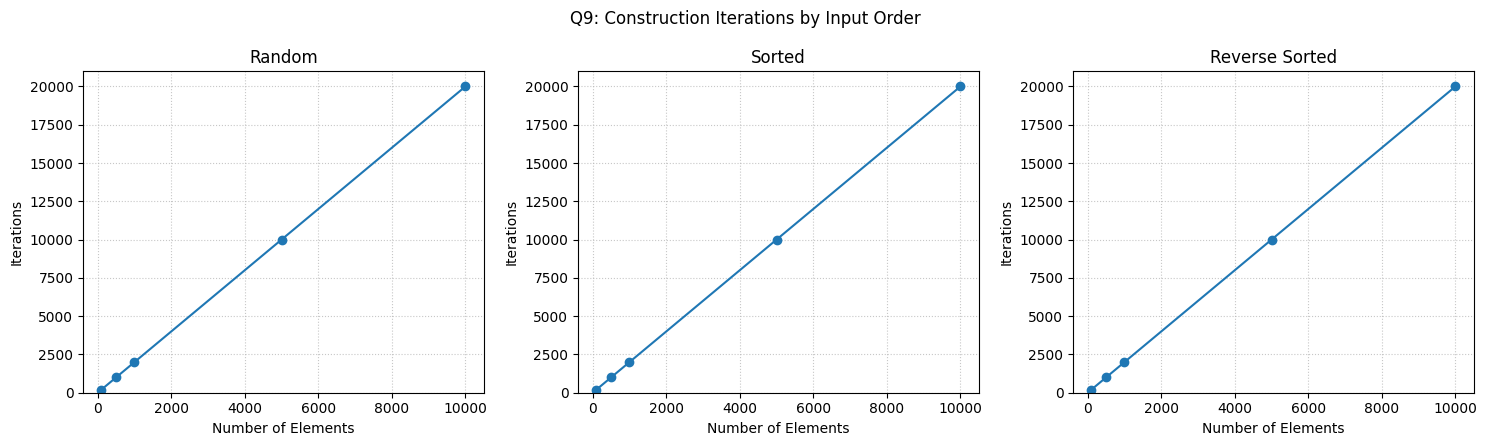

In [23]:
plot_metric_by_order(task9_df, {"Segment Tree": "Construction Iterations"}, "Iterations",
                     "Q9: Construction Iterations by Input Order", "q9_construction.png")

## Range Query Comparison

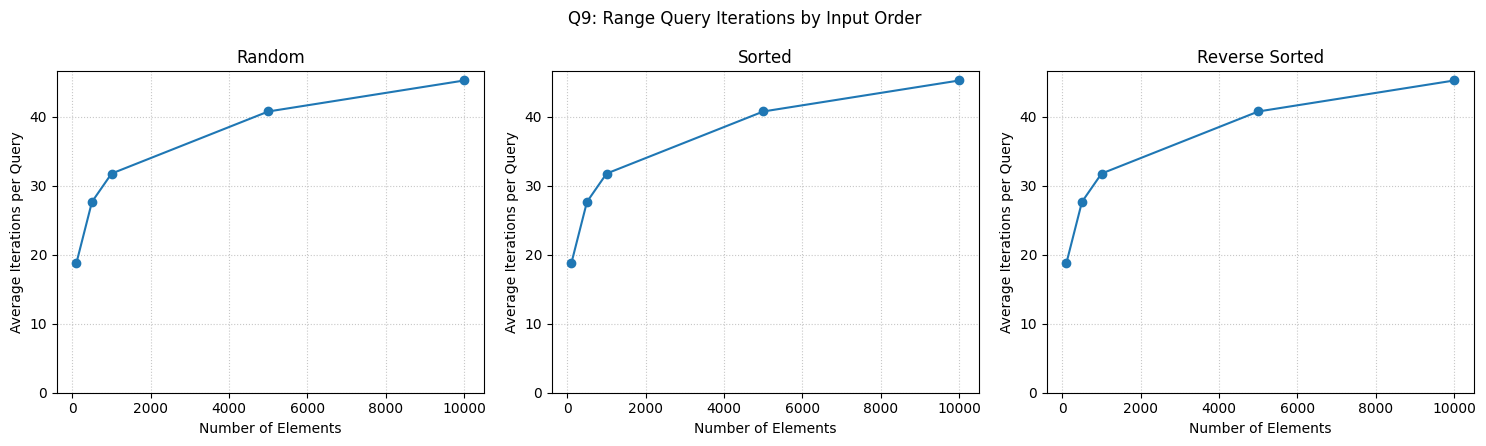

In [24]:
plot_metric_by_order(task9_df, {"Segment Tree": "Average Query Iterations"}, "Average Iterations per Query",
                     "Q9: Range Query Iterations by Input Order", "q9_query.png")

## Point Update Comparison

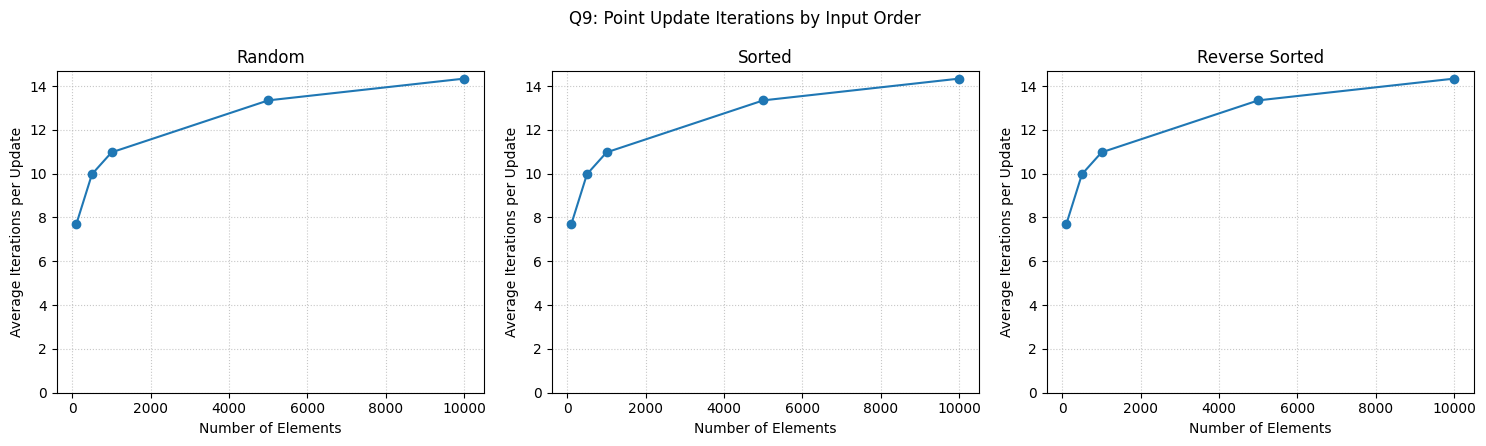

In [25]:
plot_metric_by_order(task9_df, {"Segment Tree": "Average Update Iterations"}, "Average Iterations per Update",
                     "Q9: Point Update Iterations by Input Order", "q9_update.png")

## Height Comparison

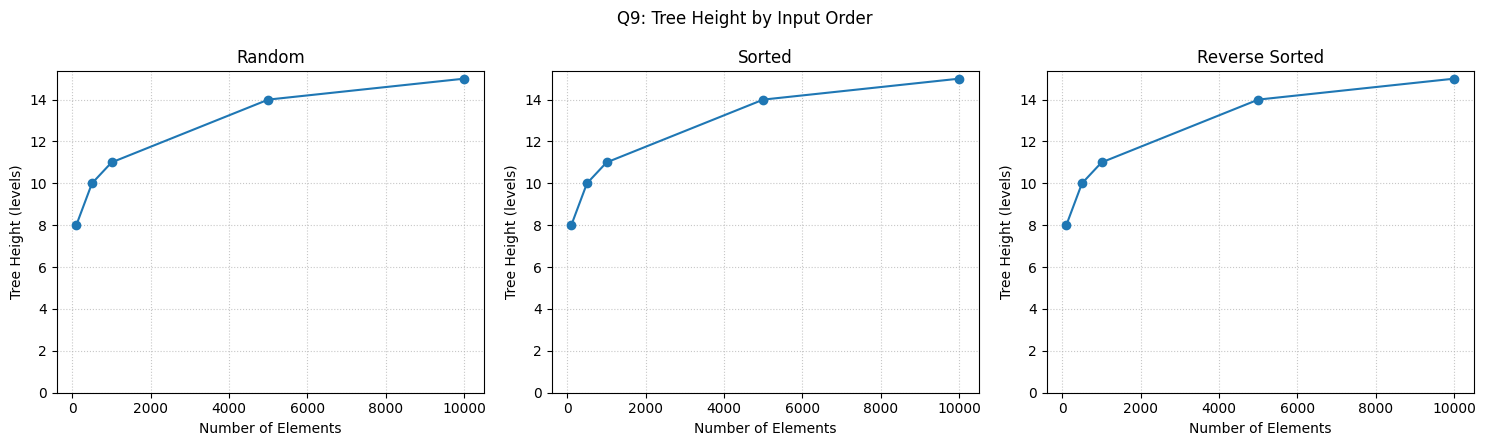

In [26]:
plot_metric_by_order(task9_df, {"Segment Tree": "Height"}, "Tree Height (levels)",
                     "Q9: Tree Height by Input Order", "q9_height.png")

## Segment Tree v/s Linear Search Comparison

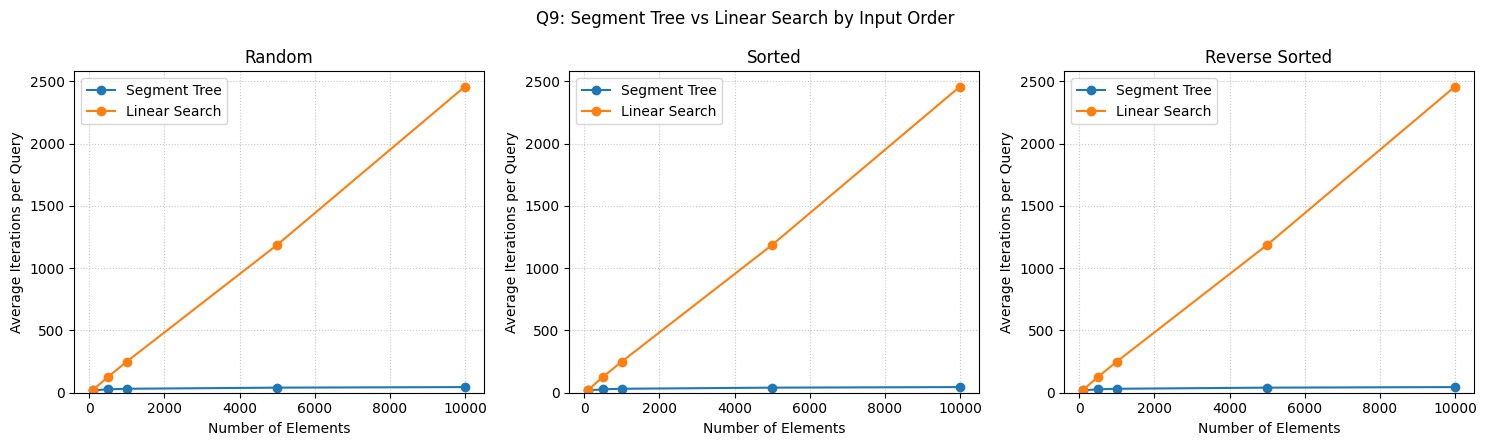

In [27]:
plot_metric_by_order(task9_df, {"Segment Tree": "Average Query Iterations",
                                "Linear Search": "Average Linear Search Iterations"},
                     "Average Iterations per Query",
                     "Q9: Segment Tree vs Linear Search by Input Order", "q9_query_vs_linear.png")

## Analysis (Q9)

Costs are iteration counts (one node visited, or one element scanned for the linear search); values below are read from the Q9 table above.

* **The input order has no effect on the Segment Tree.** For every size, random, sorted and reverse-sorted data give *identical* height, construction, query and update costs (for example at *n* = 10000: height 15, 19999 construction iterations, 45.3 query iterations, 14.3 update iterations in all three cases). The shape of the tree and the path of every operation depend only on *n* and on the indices involved, never on the stored values, so data order can only change which minimum and maximum are reported. The linear search is order-independent as well, because it always scans all `R - L + 1` elements of the range. This is in contrast to the unbalanced BST of lab 4, whose cost depends heavily on the input order.
* **Height** is exactly ⌈log₂ *n*⌉ + 1 levels: 8, 10, 11, 14 and 15 for *n* = 100, 500, 1000, 5000 and 10000.
* **Construction** visits exactly 2*n* - 1 nodes (199, 999, 1999, 9999 and 19999), i.e. it grows linearly with *n*.
* **Range query**: growing *n* by a factor of 100 (100 to 10000) increases the average cost only from 18.7 to 45.3 iterations (about 2.4 times), and it stays below 4 x height (4 x 15 = 60 at *n* = 10000).
* **Point update**: the cost is the depth of the updated leaf plus one, so it never exceeds the height (7.7 iterations on average for *n* = 100 and 14.3 for *n* = 10000, against heights of 8 and 15).
* **Segment Tree vs. linear search**: the linear search grows proportionally to *n* (about 22 iterations per query at *n* = 100 and about 2459 at *n* = 10000, roughly 110 times more). For uniformly random ranges the expected range length is about *n*/4, which matches the measured values up to sampling noise (100 ranges per window). At small sizes the two approaches are close (18.7 vs. 22.2 iterations at *n* = 100); at *n* = 10000 the Segment Tree is about 54 times cheaper per query. The price is that a Segment Tree needs O(*n*) extra memory and an O(log *n*) update, whereas a plain array updates in O(1).
* **Caveat.** An iteration is not the same amount of work for the two approaches: a node visit of the Segment Tree includes a `merge`, an element scan only one comparison pair. The comparison therefore shows how the costs grow, not their exact ratio in seconds. The random window of `input0.txt` is not uniformly random in value, but this cannot affect any result above since no cost depends on the values.

# Q10.

Analyze and report the time and space complexity of:

- Segment Tree construction
- Range Minimum/Maximum Query
- Point Update
- Linear range search

Let *N* be the number of elements and *h* = ⌈log₂ *N*⌉ + 1 the height of the tree.

| Operation | Time | Extra space | Justification (and measured confirmation) |
|:--|:--|:--|:--|
| Construction `build()` | O(*N*) | O(*N*) | T(*N*) = 2T(*N*/2) + O(1), i.e. every one of the 2*N* - 1 nodes is created once. Measured: exactly 2*n* - 1 iterations. |
| Range Min/Max Query `query(L, R)` | O(log *N*) | O(log *N*) recursion stack | At every level at most two segments are only partially covered and are expanded, so at most 4 nodes per level are visited (at most 4*h*). Measured: 18.7 to 45.3 iterations for *n* = 100 to 10000. |
| Point Update `update(i, v)` | O(log *N*) | O(log *N*) recursion stack | A single root-to-leaf path is visited and re-merged on the way back, so at most *h* nodes. Measured: 7.7 to 14.3 iterations on average, never above *h*. |
| Linear range search | O(*N*) worst case, Θ(R - L + 1) per query | O(1) with a loop; O(R - L + 1) in the recursive version above | Every element of the range is scanned once. Measured: about *n*/4 iterations on average for random ranges. |
| Segment Tree (storage) | - | O(*N*) | Two arrays (minimum and maximum) of 4*N* slots are allocated, of which 2*N* - 1 are used. |

For comparison, a point update of the plain array used by the linear search costs O(1), so the Segment Tree trades a logarithmic update and linear extra memory for a logarithmic instead of linear range query.